# ۳ — اجرای Min-Max، Z-Score و Decimal Scaling روی هر دو دیتاست

بر اساس فایل خروجی نوت‌بوک شماره ۱، سه روش در سطح تک‌تک ویژگی‌ها پیاده می‌شوند:

- **Min-Max:** `(x - min) / (max - min)`
- **Z-Score:** `(x - mean) / std`
- **Decimal Scaling:** `x / 10**j` که `j` طوری تعیین می‌شود که بیشترین قدرمطلق داده‌های train مقیاس‌شده کمتر از ۱ باشد.

**استاندارد درست برای پروژه ML:** پارامترهای هر دیتاست را فقط روی **Train** محاسبه و بعد همان پارامترها را روی Validation/Test اعمال می‌کنیم (جلوگیری از نشت داده). مقادیر Min-Max در Validation/Test ممکن است بیرون بازه [0,1] قرار بگیرند؛ این خطا نیست. اگر استاد صرفاً نرمال‌سازی توصیفی روی کل داده را بخواهد، تنظیم `FIT_ON_TRAIN_ONLY=False` را تغییر بده.

In [1]:
# Setup for Google Colab (runs automatically if inside Colab)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    if not Path('/content/drive').exists():
        drive.mount('/content/drive')
        print("Google Drive mounted at /content/drive")


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Automatic project root detection (works in local project root, notebooks directory, or Google Colab)
def find_project_root():
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path('/content/drive/MyDrive/project'),
        Path('/content/drive/MyDrive/Detecting Silent Failures of Uncertainty Estimators'),
        Path('/content/drive/MyDrive'),
        Path('/content'),
    ]
    for cand in candidates:
        if (cand / 'outputs' / 'numeric_features.csv').exists():
            return cand
    for cand in candidates:
        if (cand / 'datasets' / 'commonsense_qa').exists():
            return cand
    return Path.cwd()

ROOT = find_project_root()
OUTPUT = ROOT / 'outputs'
CHARTS = OUTPUT / 'charts'
CHARTS.mkdir(parents=True, exist_ok=True)
path = OUTPUT / 'numeric_features.csv'
if not path.exists():
    raise FileNotFoundError('First run 01_prepare_numeric_features.ipynb')

data = pd.read_csv(path)
FEATURES = ['question_words', 'question_chars', 'avg_option_words', 'option_count']
FIT_ON_TRAIN_ONLY = True
print(f'Project ROOT: {ROOT}')
print('Rows:', len(data), '| train-only fitting:', FIT_ON_TRAIN_ONLY)


Project ROOT: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators
Rows: 14692 | train-only fitting: True


## ۱. محاسبه پارامترها و اجرای سه روش

In [3]:
def decimal_exponent(training_values):
    a=np.asarray(training_values,dtype=float)
    a=a[np.isfinite(a)]
    if len(a)==0 or np.max(np.abs(a))<1:
        return 0
    return int(np.floor(np.log10(float(np.max(np.abs(a)))))+1)

normalized=[]
params=[]
for name,group in data.groupby('dataset',sort=False):
    sub=group.copy()
    fit=sub[sub['split'].eq('train')] if FIT_ON_TRAIN_ONLY else sub
    if len(fit)==0:
        raise ValueError(f'{name}: no train samples, cannot fit train-only normalization')
    for feat in FEATURES:
        train=pd.to_numeric(fit[feat],errors='coerce').to_numpy(dtype=float)
        valid=train[np.isfinite(train)]
        if len(valid)==0:
            raise ValueError(f'{name}/{feat}: no valid values in fitting split')
        lo,hi=float(valid.min()),float(valid.max())
        mu=float(valid.mean()); sd=float(valid.std(ddof=0))
        j=decimal_exponent(valid)
        x=pd.to_numeric(sub[feat],errors='coerce').to_numpy(dtype=float)
        sub[f'{feat}__minmax']=(x-lo)/(hi-lo) if hi>lo else np.where(np.isfinite(x),0.0,np.nan)
        sub[f'{feat}__zscore']=(x-mu)/sd if sd>0 else np.where(np.isfinite(x),0.0,np.nan)
        sub[f'{feat}__decimal']=x/(10**j)
        params.append({'dataset':name,'feature':feat,'fitted_on':'train' if FIT_ON_TRAIN_ONLY else 'all_splits',
                       'min':lo,'max':hi,'mean':mu,'population_std':sd,'decimal_exponent_j':j,
                       'constant_feature':bool(hi==lo)})
    normalized.append(sub)
result=pd.concat(normalized,ignore_index=True)
parameter_table=pd.DataFrame(params)
display(parameter_table.round(4))
display(result.head(8))
result.to_csv(OUTPUT/'normalized_features.csv',index=False,encoding='utf-8-sig')
parameter_table.to_csv(OUTPUT/'normalization_parameters.csv',index=False,encoding='utf-8-sig')

,dataset,feature,fitted_on,min,max,mean,population_std,decimal_exponent_j,constant_feature
0,CommonsenseQA,question_words,train,3.0,63.0,13.2520,5.5189,2,False
1,CommonsenseQA,question_chars,train,15.0,376.0,69.4669,29.4616,3,False
2,CommonsenseQA,avg_option_words,train,1.0,6.0,1.5210,0.4094,1,False
3,CommonsenseQA,option_count,train,5.0,5.0,5.0000,0.0000,1,True
4,ARC-Challenge,question_words,train,5.0,111.0,21.8588,13.7113,3,False
5,ARC-Challenge,question_chars,train,22.0,683.0,126.3718,80.0067,3,False
6,ARC-Challenge,avg_option_words,train,1.0,18.5,4.9016,3.2054,2,False
7,ARC-Challenge,option_count,train,3.0,5.0,4.0000,0.0423,1,False


,dataset,split,source_file,source_row,question_words,question_chars,avg_option_words,option_count,question_words__minmax,question_words__zscore,question_words__decimal,question_chars__minmax,question_chars__zscore,question_chars__decimal,avg_option_words__minmax,avg_option_words__zscore,avg_option_words__decimal,option_count__minmax,option_count__zscore,option_count__decimal
0,CommonsenseQA,test,data\test-00000-of-00001.parquet,0,18,85,1.6,5,0.250000,0.860314,0.18,0.193906,0.527232,0.085,0.12,0.193087,0.16,0.0,0.0,0.5
1,CommonsenseQA,test,data\test-00000-of-00001.parquet,1,13,64,1.4,5,0.166667,-0.045666,0.13,0.135734,-0.185560,0.064,0.08,-0.295448,0.14,0.0,0.0,0.5
2,CommonsenseQA,test,data\test-00000-of-00001.parquet,2,14,65,1.6,5,0.183333,0.135530,0.14,0.138504,-0.151617,0.065,0.12,0.193087,0.16,0.0,0.0,0.5
3,CommonsenseQA,test,data\test-00000-of-00001.parquet,3,9,49,2.0,5,0.100000,-0.770450,0.09,0.094183,-0.694697,0.049,0.20,1.170156,0.20,0.0,0.0,0.5
4,CommonsenseQA,test,data\test-00000-of-00001.parquet,4,9,51,1.2,5,0.100000,-0.770450,0.09,0.099723,-0.626812,0.051,0.04,-0.783983,0.12,0.0,0.0,0.5
5,CommonsenseQA,test,data\test-00000-of-00001.parquet,5,23,119,1.2,5,0.333333,1.766294,0.23,0.288089,1.681277,0.119,0.04,-0.783983,0.12,0.0,0.0,0.5
6,CommonsenseQA,test,data\test-00000-of-00001.parquet,6,10,47,1.0,5,0.116667,-0.589254,0.10,0.088643,-0.762582,0.047,0.00,-1.272517,0.10,0.0,0.0,0.5
7,CommonsenseQA,test,data\test-00000-of-00001.parquet,7,11,63,1.2,5,0.133333,-0.408058,0.11,0.132964,-0.219502,0.063,0.04,-0.783983,0.12,0.0,0.0,0.5


## ۲. نمونه مقایسه مقادیر قبل و بعد نرمال‌سازی

In [4]:
for name,group in result.groupby('dataset',sort=False):
    feature='question_words'
    names=[feature]+[f'{feature}__{method}' for method in ('minmax','zscore','decimal')]
    print(name)
    display(group[['split',*names]].head(12).round(4))

CommonsenseQA


,split,question_words,question_words__minmax,question_words__zscore,question_words__decimal
0,test,18,0.2500,0.8603,0.18
1,test,13,0.1667,-0.0457,0.13
2,test,14,0.1833,0.1355,0.14
3,test,9,0.1000,-0.7705,0.09
4,test,9,0.1000,-0.7705,0.09
5,test,23,0.3333,1.7663,0.23
6,test,10,0.1167,-0.5893,0.10
7,test,11,0.1333,-0.4081,0.11
8,test,7,0.0667,-1.1328,0.07
9,test,13,0.1667,-0.0457,0.13


ARC-Challenge


,split,question_words,question_words__minmax,question_words__zscore,question_words__decimal
12102,test,23,0.1698,0.0832,0.023
12103,test,42,0.3491,1.4689,0.042
12104,test,22,0.1604,0.0103,0.022
12105,test,48,0.4057,1.9065,0.048
12106,test,46,0.3868,1.7607,0.046
12107,test,53,0.4528,2.2712,0.053
12108,test,50,0.4245,2.0524,0.050
12109,test,24,0.1792,0.1562,0.024
12110,test,45,0.3774,1.6877,0.045
12111,test,24,0.1792,0.1562,0.024


## ۳. مقایسه نمودارهای سه روش نرمال‌سازی

محورهای x متفاوت‌اند، چون هر روش مقیاس متفاوتی دارد. **هیچ‌یک از این سه تبدیل خطی/مقیاسی به خودی خود داده کج‌چوله را نرمال نمی‌کند.**

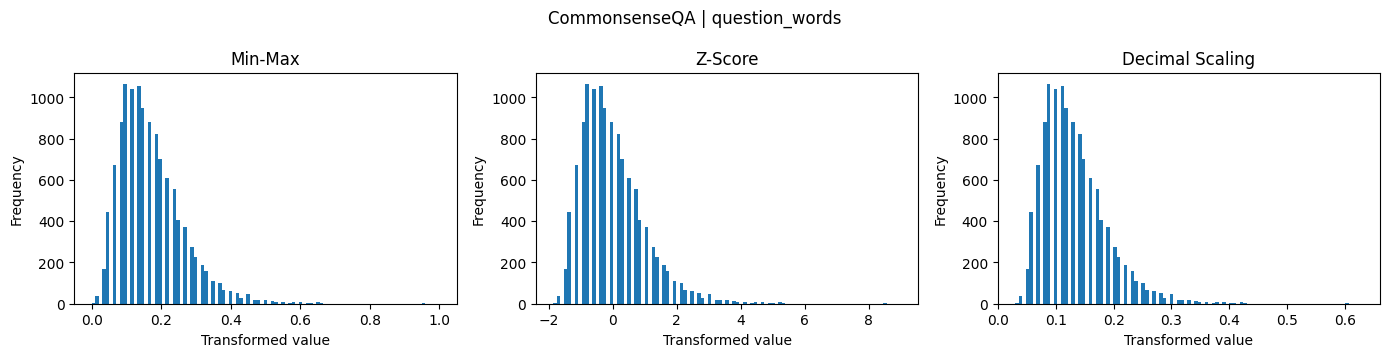

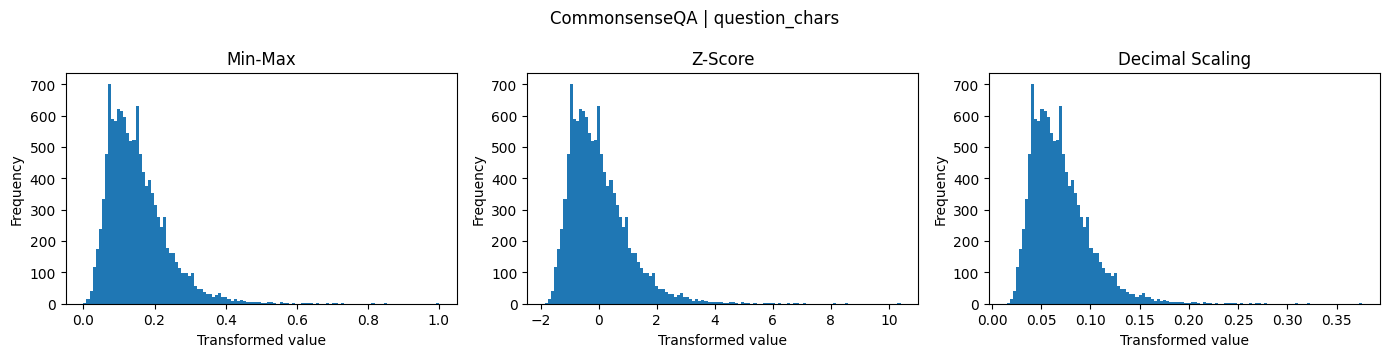

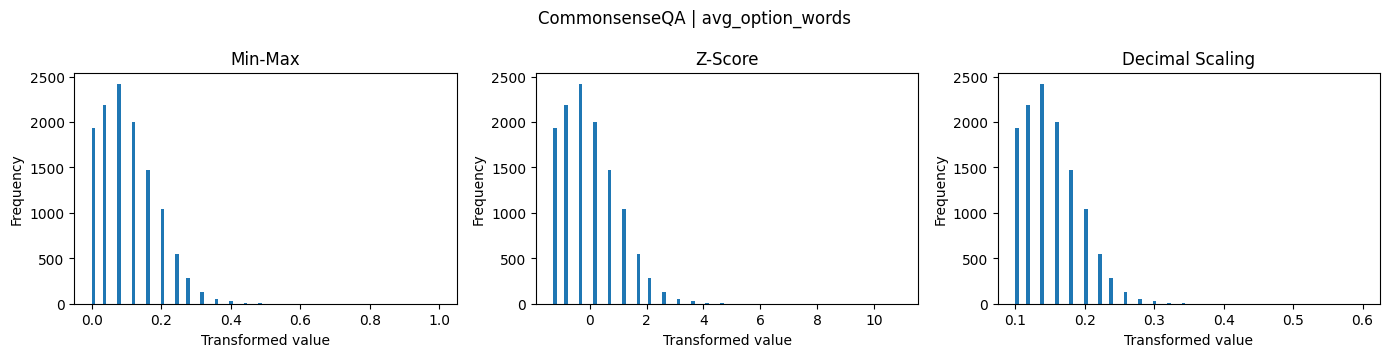

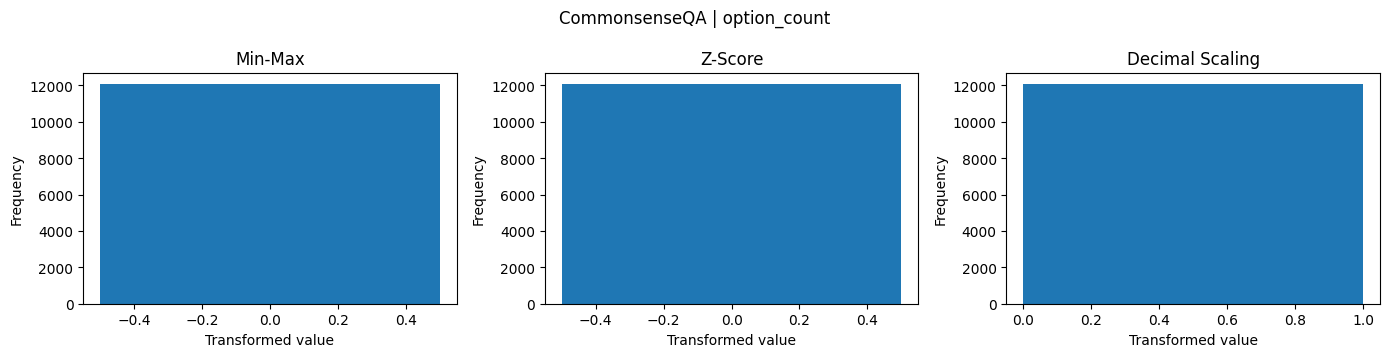

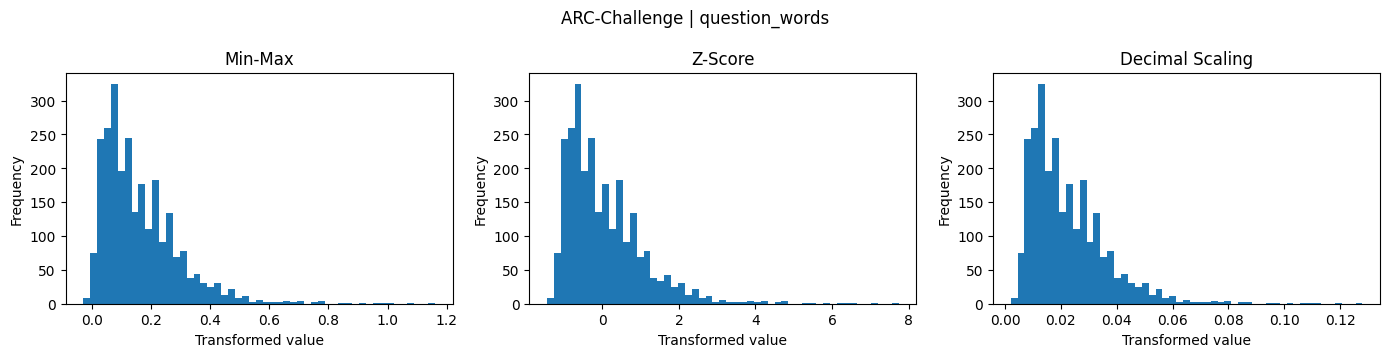

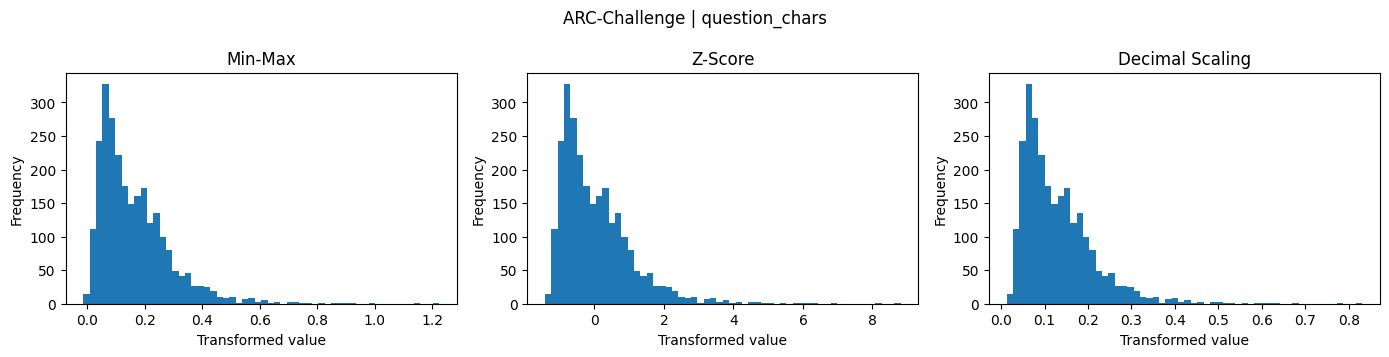

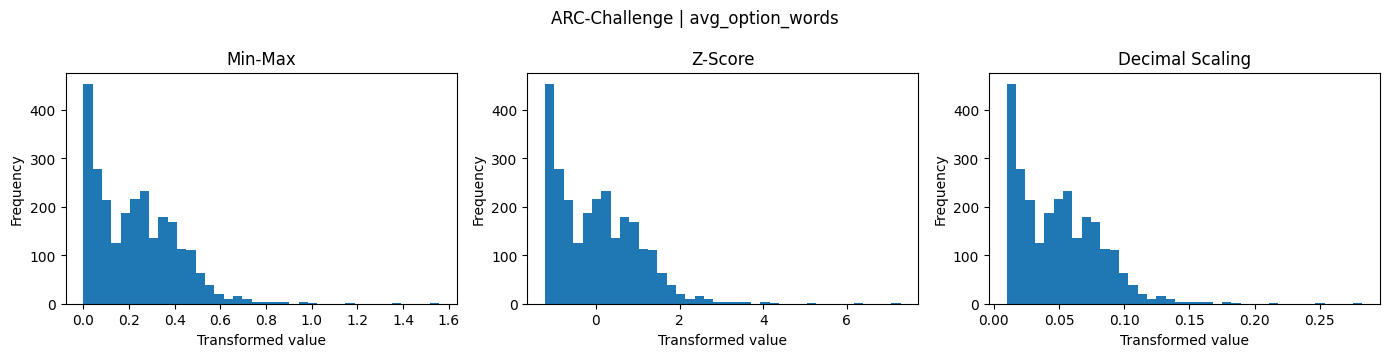

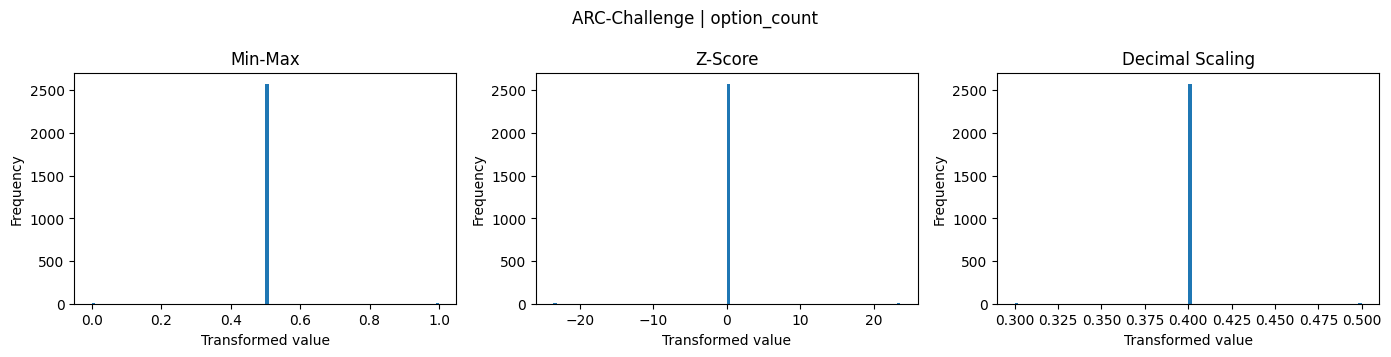

Comparison charts saved at D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\charts


In [5]:
for name,group in result.groupby('dataset',sort=False):
    for feat in FEATURES:
        fig,axes=plt.subplots(1,3,figsize=(14,3.6))
        for ax,method,title in zip(axes,('minmax','zscore','decimal'),
                                   ('Min-Max','Z-Score','Decimal Scaling')):
            x=group[f'{feat}__{method}'].dropna().to_numpy(dtype=float)
            if len(x):
                if np.max(x)==np.min(x):
                    ax.hist(x,bins=[x[0]-.5,x[0]+.5])
                else:
                    ax.hist(x,bins='auto')
            ax.set_title(title)
            ax.set_xlabel('Transformed value')
            ax.set_ylabel('Frequency')
        fig.suptitle(f'{name} | {feat}')
        fig.tight_layout()
        fname=f"{name.lower().replace('-','_')}_{feat}_normalizations.png"
        fig.savefig(CHARTS/fname,dpi=160,bbox_inches='tight')
        plt.show();plt.close(fig)
print('Comparison charts saved at',CHARTS)

## ۴. کنترل کیفیت و ذخیره گزارش کوتاه

چون Min-Max فقط روی train آموزش داده شده، برای Validation/Test ممکن است خارج ۰ تا ۱ باشد. این موارد به‌صورت جداگانه گزارش می‌شوند.

In [6]:
checks=[]
for (name,split),group in result.groupby(['dataset','split'],sort=False):
    for feat in FEATURES:
        x=group[f'{feat}__minmax'].dropna()
        outside=int(((x<0)|(x>1)).sum())
        checks.append({'dataset':name,'split':split,'feature':feat,
                       'n_valid':len(x),'minmax_outside_0_1':outside,
                       'minmax_min':float(x.min()) if len(x) else np.nan,
                       'minmax_max':float(x.max()) if len(x) else np.nan})
quality=pd.DataFrame(checks)
display(quality)
quality.to_csv(OUTPUT/'normalization_quality_checks.csv',index=False,encoding='utf-8-sig')
print('Done. No LLM inference; original downloaded datasets remain unchanged.')

,dataset,split,feature,n_valid,minmax_outside_0_1,minmax_min,minmax_max
0,CommonsenseQA,test,question_words,1140,0,0.016667,0.950000
1,CommonsenseQA,test,question_chars,1140,0,0.024931,0.847645
2,CommonsenseQA,test,avg_option_words,1140,0,0.000000,0.400000
3,CommonsenseQA,test,option_count,1140,0,0.000000,0.000000
4,CommonsenseQA,train,question_words,9741,0,0.000000,1.000000
5,CommonsenseQA,train,question_chars,9741,0,0.000000,1.000000
6,CommonsenseQA,train,avg_option_words,9741,0,0.000000,1.000000
7,CommonsenseQA,train,option_count,9741,0,0.000000,0.000000
8,CommonsenseQA,validation,question_words,1221,0,0.000000,0.800000
9,CommonsenseQA,validation,question_chars,1221,0,0.016620,0.731302


Done. No LLM inference; original downloaded datasets remain unchanged.
